# Integration Method by Matt (Example using `IndShockConsumer`) [WIP]

Constructing End of Period (Marginal) Value Function using Transitionmatrices instead of Expectations.
This notebook shows the necessary steps to construct the function. For simplicity, we will only focus on transitory shock without unemployment probability nor permanent shocks.

To illustrate concepts, I construct the End of Period Marginal Value Function in the following ways:
1. Traditional way with one expectation step
2. Splitting up expectations with two steps (One for each shock)
3. Replacing expectations of transitory shocks with Transition matrices

Idea by Matt White
Code by Adrian Monninger

> **Note — this is a modified copy of `Test_Integration_IndShock_Versions_Unemp.ipynb`.**
>
> ## The fix: quadrature-weighted transition matrix
>
> **Problem.** The transition matrix $P$ maps the exogenous end-of-period grid $b$ to next-period market resources $m$ via the transitory-shock density $g$, where $m = b + \theta$ and $\theta \sim g$. In the original notebook each row is built as
> $$ P[b_i, m_j] \;=\; \frac{g(m_j - b_i)}{\sum_k g(m_k - b_i)} . $$
> This is only a valid discretization of $\int f(m)\, g(m-b)\, dm$ when the $m$-grid is **uniformly** spaced. Here `mGrid` is built with `make_grid_exp_mult`, so it is exponentially spaced: points are dense at low $m$ and sparse at high $m$. The plain row-sum implicitly assigns every column the same quadrature weight, so it **over-weights the dense (low-$m$) region and under-weights the sparse (high-$m$) region**. The resulting conditional expectation
> $$ \mathbb{E}[f(m)\mid b] \;=\; \sum_j P[b,m_j]\, f(m_j) $$
> is biased, and — crucially — the bias does **not** disappear as the grid is refined, because refining an exponential grid does not make it uniform.
>
> **Fix.** Weight each column by the local grid spacing $\Delta m_j$ before normalizing, turning the sum into a proper trapezoidal/Riemann approximation:
> $$ P[b_i, m_j] \;=\; \frac{g(m_j - b_i)\,\Delta m_j}{\sum_k g(m_k - b_i)\,\Delta m_k}, \qquad \Delta m_j \approx \tfrac{1}{2}(m_{j+1}-m_{j-1}). $$
> In code this is a single added line, `probGrid *= np.gradient(mGrid)`, applied before the existing row normalization. The row normalization is retained: it now only rescales away the small amount of probability mass that falls outside `[mGridMin, mGridMax]`, rather than compensating for uneven grid spacing.
>
> The correction is applied to both `updateBM_TranMatrix` (transitory shock only) and `updateBM_TranMatrix_withUnemp` (employed/unemployed mixture). See the code comments marked `# --- FIX ---` below.

# Creating End-of-Period Marginal Value Function

1. Calculating both shocks together:
$$
m_{t+1} = a_t R/ \psi + \theta
$$

$$
V(a) = EV(m_{t+1}) = \sum_i \sum_j \pi_i \pi_j V(a_t * R/ \psi_j + \theta_i)
$$

While we do only one calculation, we need to loop over many points. If we approximate both shocks with 7 points each, the loop is 7x7 = 49 for each point of the a-grid. As both shocks are IID, we can split them up

2. Two shocks individually

$$
b_{t+1} = a_t * R/ \psi_j \\
m_{t+1} = b_{t+1} + \theta
$$

1. Transitory shock
$$
V(b) = EV(m_{t+1}) = \sum_i \pi_i V(b_{t+1}+ \theta_i)
$$

2. Permanent shock
$$
V(a) = EV(m_{t+1}) = \sum_j \pi_j V(b_{t+1})
$$

Now, each step has a loop over 7 points. Therefore, we have 7 x 2 = 14 instead of 49.

3. Transition matrices

Lastly, we want to approximate the transitory shock by more points using transition matrices. (Integration method by Matt White).

This version also includes unemployment probability. As the transition matrix method does not allow for point-masses, income at unemployment is normally distributed as well.

In [111]:
from HARK.interpolation import LinearInterp, MargValueFuncCRRA
from HARK.econforgeinterp import LinearFast
from HARK.ConsumptionSaving.ConsIndShockModel import IndShockConsumerType
import numpy as np

from HARK.distribution import (
    expected,
)

import matplotlib.pyplot as plt

from HARK.utilities import make_grid_exp_mult
import scipy as sp

In [112]:
T_cycles = 2
PermShk = 0.06
TranShk = 0.2
ShockCount = 21
UnempPrb = 0.05
IncUnemp = 0.7
CRRA = 2
Rfree = 1.04**.25
DiscFac = 0.975
PermGroFac = 1.0
LivPrb = 0.99375
DiscFacEff = DiscFac * LivPrb

Dict={
    "CRRA": CRRA,
    "Rfree": [Rfree] * T_cycles,                   # Interest factor on assets
    "DiscFac": DiscFac,                     # Intertemporal discount factor
    "LivPrb" : [LivPrb] * T_cycles, #[0.999], #[.99375],                  # Survival probability
    "PermGroFac" : [PermGroFac] * T_cycles,                 # Permanent income growth factor

    # Parameters that specify the income distribution over the lifecycle
    "PermShkStd" :   [PermShk] * T_cycles, #[.06],                 # Standard deviation of log permanent shocks to income
    "PermShkCount" : ShockCount,                    # Number of points in discrete approximation to permanent income shocks
    "TranShkStd" : [TranShk] * T_cycles, #[.2],                   # Standard deviation of log transitory shocks to income
    "TranShkCount" : ShockCount,                    # Number of points in discrete approximation to transitory income shocks
    "UnempPrb" : [UnempPrb] * T_cycles,                     # Probability of unemployment while working
    "IncUnemp" :  [IncUnemp] * T_cycles,                      # Unemployment benefits replacement rate
    "UnempPrbRet" : [0.0] * T_cycles,                # Probability of "unemployment" while retired
    "IncUnempRet" : [0.0] * T_cycles,                   # "Unemployment" benefits when retired
    "T_cycle" : T_cycles,                         # Number of periods in the cycle for this agent type
    "max_cycles": 5000,

}

In [113]:
IndShock = IndShockConsumerType(**Dict)
IndShock.update()
IndShock.solve()

In [114]:
t = 1
tNext = 2

In [115]:
### Get Last Period Marginal Value Function and grids
# cFuncNext = IndShock.solution[1].cFunc
# vPfuncNext = MargValueFuncCRRA(cFuncNext, CRRA)
vPfuncNext = IndShock.solution[tNext].vPfunc
aXtraGrid = IndShock.aXtraGrid
mNrmMinNext = IndShock.solution[tNext].mNrmMin

### Shocks
IncShkDstn = IndShock.IncShkDstn[t]
ShkPrbsNext = IncShkDstn.pmv
PermShkValsNext = IncShkDstn.atoms[0]
TranShkValsNext = IncShkDstn.atoms[1]
PermShkMinNext = np.min(PermShkValsNext)
TranShkMinNext = np.min(TranShkValsNext)

# Borrowing Constraint
BoroCnstNat = (
    (IndShock.solution[tNext].mNrmMin - TranShkMinNext)
    * (IndShock.PermGroFac[t] * PermShkMinNext)
    / IndShock.Rfree[t] )

BoroCnstNat_b = BoroCnstNat  - ( TranShkMinNext * (PermGroFac * PermShkMinNext)/ Rfree)


# (
#     (IndShock.solution[tNext].mNrmMin - TranShkMinNext - TranShkMinNext)
#     * (IndShock.PermGroFac[t] * PermShkMinNext * PermShkMinNext)
#     / IndShock.Rfree[t] )
aNrmNow = np.asarray(aXtraGrid) + BoroCnstNat

In [116]:
BoroCnstNat, BoroCnstNat_b, aNrmNow[:5]

(-0.5742725818701606,
 -1.1485451637403212,
 array([-0.57327258, -0.55410121, -0.53380798, -0.51230365, -0.48948989]))

In [117]:
def m_nrm_next(PermGroFac, shocks, a_nrm, Rfree):
    """
    Computes normalized market resources of the next period
    from income shocks and current normalized market resources.

    Parameters
    ----------
    shocks: [float]
        Permanent and transitory income shock levels.
    a_nrm: float
        Normalized market assets this period

    Returns
    -------
    float
        normalized market resources in the next period
    """
    return Rfree / (PermGroFac * shocks["PermShk"]) * a_nrm + shocks["TranShk"]

In [118]:
### End-of-period Marginal Value Function (Traditional Way)

def vp_next(shocks, a_nrm, Rfree):
    return shocks["PermShk"] ** (-CRRA) * vPfuncNext(
        m_nrm_next(PermGroFac, shocks, a_nrm, Rfree)
    )

EndOfPrdvP = (
    DiscFacEff
    * Rfree
    * PermGroFac ** (-CRRA)
    * expected(vp_next, IncShkDstn, args=(aNrmNow, Rfree))
        )

(0.0, 2.0)

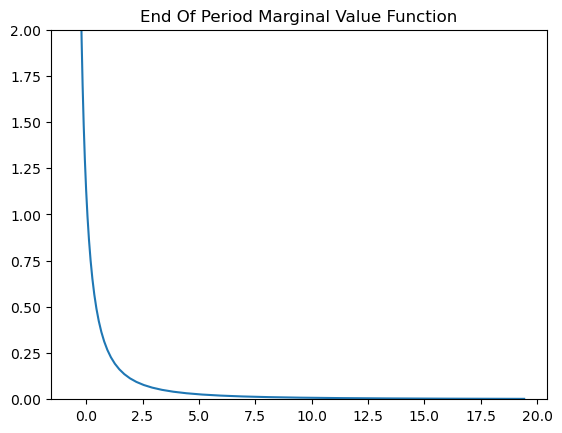

In [119]:
plt.plot(aNrmNow, EndOfPrdvP)
plt.title('End Of Period Marginal Value Function')
plt.ylim([0.0, 2.0])

## Test 1: Split up Shocks in 2 distinct steps



In [120]:
bNrmNow = aNrmNow # Create a grid for bank balances

### Transitory Shock $b_{t+1} \to m_{t+1}$

$$
m_{t+1} = b_{t+1} + \theta
$$

In [121]:
def m_nrm_next_twostep(b_nrm, shocks):
    """
    Computes normalized market resources of the next period
    from income shocks and current normalized market resources.

    Parameters
    ----------
    shocks: [float]
        Permanent and transitory income shock levels.
    b_nrm: float
        Normalized bank balanaces this period

    Returns
    -------
    float
        normalized market resources in the next period
    """
    return b_nrm + shocks["TranShk"]

In [122]:
def vp_next_Interim(shocks, b_nrm):
    return vPfuncNext(
        m_nrm_next_twostep(b_nrm, shocks)
    )

Interm_vP = (
expected(vp_next_Interim, IncShkDstn, args=(bNrmNow))
        )

(0.0, 2.0)

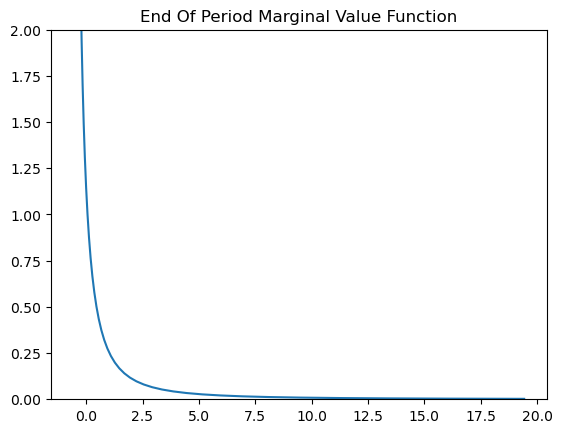

In [123]:
plt.plot(bNrmNow, Interm_vP)
plt.title('End Of Period Marginal Value Function')
plt.ylim([0.0, 2.0])

In [124]:
### Make a function
# 1) Take the inverse of the interim marginal value function
Interm_vPnvrs = Interm_vP.flatten() ** (-1 / CRRA)

# 2) Add a zero point
bNrmNow_Interp = np.insert(bNrmNow, 0, 0.0)
Interm_vPnvrs_Interp = np.insert(Interm_vPnvrs, 0, 0.0)

# 3) Interpolate
Interm_vPnvrsFunc = LinearFast(Interm_vPnvrs_Interp, [bNrmNow_Interp])

Interm_vPfunc = MargValueFuncCRRA(Interm_vPnvrsFunc, CRRA)

### Permanent shock $a_t \to b_{t+1}$
$$
b_{t+1} = a_t * R/ \psi_j
$$

In [125]:
def b_nrm_next(PermGroFac, shocks, a_nrm, Rfree):
    """
    Computes normalized market resources of the next period
    from income shocks and current normalized market resources.

    Parameters
    ----------
    shocks: [float]
        Permanent and transitory income shock levels.
    a_nrm: float
        Normalized market assets this period

    Returns
    -------
    float
        normalized market resources in the next period
    """
    return Rfree / (PermGroFac * shocks["PermShk"]) * a_nrm

In [126]:
def vp_next_TwoStep(shocks, a_nrm, Rfree):
    return shocks["PermShk"] ** (-CRRA) * Interm_vPfunc(
        b_nrm_next(PermGroFac, shocks, a_nrm, Rfree)
    )

EndOfPrdvP_TwoStep = (
    DiscFacEff
    * Rfree
    * PermGroFac ** (-CRRA)
    * expected(vp_next_TwoStep, IncShkDstn, args=(aNrmNow, Rfree))
        )

(0.0, 2.0)

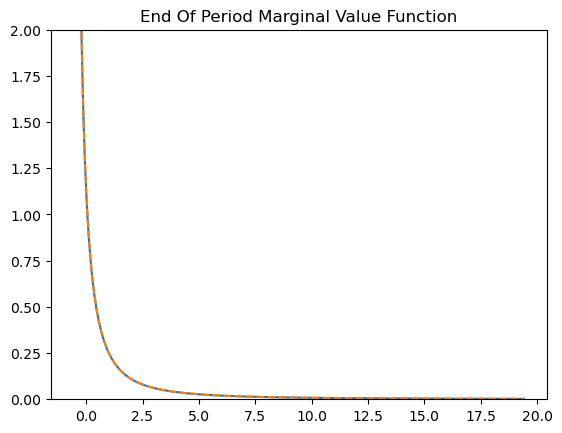

In [127]:
plt.plot(aNrmNow, EndOfPrdvP)
plt.plot(aNrmNow, EndOfPrdvP_TwoStep, '--')
plt.title('End Of Period Marginal Value Function')
plt.ylim([0.0, 2.0])

## Test 2: Using Transition Matrices for Transitory Shocks

In [128]:
### Step 1: In a pre-solution step, specify fairly dense grids of m and b, denser than the grid of a.
mGrid = make_grid_exp_mult(0.0001, 52, 310, timestonest=1)
bGrid = make_grid_exp_mult(0.0, 48, 300, timestonest=1)

### Let ist start from minimum of aNrm
# NO, WRONG MINIMUM!
mGrid = mGrid + mNrmMinNext
bGrid = bGrid + aNrmNow[0]


(0.0, 2.0)

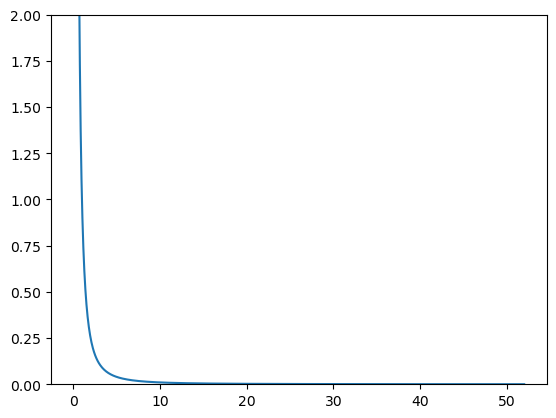

In [129]:
plt.plot(mGrid, vPfuncNext(mGrid))
plt.ylim([0.0, 2.0])

In [130]:
### Step 2: In that pre-solution step, for each $F_{\theta, t}$ (i.e. just once if this is an ifinite horizon problem), 
###         calculate $f_{\theta, t}(m - b) on the cross product of the b-grid and m-grid. 
###         Put them in a matrix that has b values by row and m values by column.
###         Still in the pre-solution step, for each b-row in the matrix, take the row-wise sum and
###         divide the row by it. This represents a Markov transition matrix from the exogenous
###         b-grid to the exogenous m-grid.

def updateBM_TranMatrix(TranShkStd, bGrid, mGrid):
    """
    Calculates the Probabillity of a transioty shock for the b times m matrix
    """
    # probGrid = np.zeros((len(self.bNrmGrid_income), len(self.mNrmGrid_income)))  # b x m
    # ### getting the probability for each transitory shock with the size b - m (remember m = b * transitory shock)

    ### Integration 1: No unemployment probability
    s = TranShkStd
    mu = -0.5 * s**2
    lognorm_dist =  sp.stats.lognorm(s, scale=np.exp(mu))

    ### Create matrix
    # Construct meshgrid of bNrmGrid_income and mNrmGrid_income
    b, m = np.meshgrid(bGrid, mGrid, indexing='ij')

    # Calculate differences between corresponding elements
    probGrid = lognorm_dist.pdf(m - b)

    # --- FIX: weight the density by the local m-grid spacing (Delta m) ---------
    # mGrid is exponentially spaced (non-uniform). The raw row-sum normalization
    # below approximates the integral of the density with a *uniform* quadrature
    # weight of 1 per column, so densely-spaced (low-m) regions get over-weighted
    # and sparsely-spaced (high-m) regions get under-weighted. This biases the
    # implied conditional expectation E[.|b] = sum_m probGrid[b,m] f(m_m) and does
    # not vanish as the grid is refined. Weighting each column by dm_j turns the
    # sum into a proper Riemann/trapezoidal approximation of
    #   int f(m) g(m-b) dm  ~=  sum_j f(m_j) g(m_j-b) dm_j,
    # after which the row normalization only removes the (small) tail mass that
    # falls outside [mGridMin, mGridMax].
    dm = np.gradient(mGrid)          # local column spacing, len == len(mGrid)
    probGrid = probGrid * dm[np.newaxis, :]
    # --------------------------------------------------------------------------

    for i_b in range(len(bGrid)):
        probGrid[i_b] = probGrid[i_b]/(np.max([np.sum(probGrid[i_b]), 0.000001]))

    return probGrid


In [131]:
def updateBM_TranMatrix_withUnemp(TranShkStd, UnempPrb, IncUnemp, IncUnemp_Std, bGrid, mGrid):
    """
    Calculates the Probabillity of a transioty shock for the b times m matrix
    """
    ### Combine the two distributions by keeping the mean of the distribution the same
    # To enure that the combined distribution has a mean of 1, we need to adjust the scale parameters
    # Adjusted mu1 to ensure the combined mean is 1
    mu_transformed = (1 - UnempPrb * IncUnemp) / (1 - UnempPrb)

    ### Transitory shock: Employed
    s_emp = TranShkStd
    mu_emp = np.log(mu_transformed) -0.5 * s_emp**2

    ### Transitory shock: Unemployed
    ### Unemployment probability: Unemployment benefits are also log normallog distributed
    s_unemp = IncUnemp_Std
    mu_unemp = np.log(IncUnemp) -0.5 * s_unemp**2

    ### Combine the two distributions but keep the mean of the distribution the same
    # Adjust the scale parameters to ensure the combined mean is 1
    lognorm_dist_emp =  sp.stats.lognorm(s=s_emp, scale=np.exp(mu_emp) )
    lognorm_dist_unemp = sp.stats.lognorm(s=s_unemp, scale=np.exp(mu_unemp))

   
    # Define the mixture PDF
    def mixture_pdf(x):
        return (1 - UnempPrb) * lognorm_dist_emp.pdf(x) + UnempPrb * lognorm_dist_unemp.pdf(x)

    ### Create matrix
    # Construct meshgrid of bNrmGrid_income and mNrmGrid_income
    b, m = np.meshgrid(bGrid, mGrid, indexing='ij')

    # Calculate differences between corresponding elements
    probGrid = mixture_pdf(m - b)

    # --- FIX: weight the density by the local m-grid spacing (Delta m) ---------
    # Same correction as in updateBM_TranMatrix: on the non-uniform (exponential)
    # mGrid, integrate the mixture density with the trapezoidal weight dm_j before
    # normalizing each row, so the transition matrix reproduces
    #   int f(m) [ (1-p) g_emp(m-b) + p g_unemp(m-b) ] dm.
    dm = np.gradient(mGrid)
    probGrid = probGrid * dm[np.newaxis, :]
    # --------------------------------------------------------------------------

    for i_b in range(len(bGrid)):
        probGrid[i_b] = probGrid[i_b]/(np.max([np.sum(probGrid[i_b]), 0.000001]))

    return probGrid

In [132]:
IncUnemp_Std = 0.1
TranShkStd = TranShk
probGrid = updateBM_TranMatrix_withUnemp(TranShk, UnempPrb, IncUnemp, IncUnemp_Std, bGrid, mGrid)

#### Show shock distribution

In [133]:
### Combine the two distributions by keeping the mean of the distribution the same
# To enure that the combined distribution has a mean of 1, we need to adjust the scale parameters
# Adjusted mu1 to ensure the combined mean is 1
mu_transformed = (1 - UnempPrb * IncUnemp) / (1 - UnempPrb)

### Integration 2: With unemployment probability
s_emp = TranShkStd
mu_emp = np.log(mu_transformed) -0.5 * s_emp**2

### Unemployment probability: Unemployment benefits are also log normallog distributed
s_unemp = IncUnemp_Std
mu_unemp = np.log(IncUnemp) -0.5 * s_unemp**2

### Combine the two distributions but keep the mean of the distribution the same
# Adjust the scale parameters to ensure the combined mean is 1
lognorm_dist_emp =  sp.stats.lognorm(s=s_emp, scale=np.exp(mu_emp) )
lognorm_dist_unemp = sp.stats.lognorm(s=s_unemp, scale=np.exp(mu_unemp))

# Define the mixture PDF
def mixture_pdf(x):
    return (1 - UnempPrb) * lognorm_dist_emp.pdf(x) + UnempPrb * lognorm_dist_unemp.pdf(x)


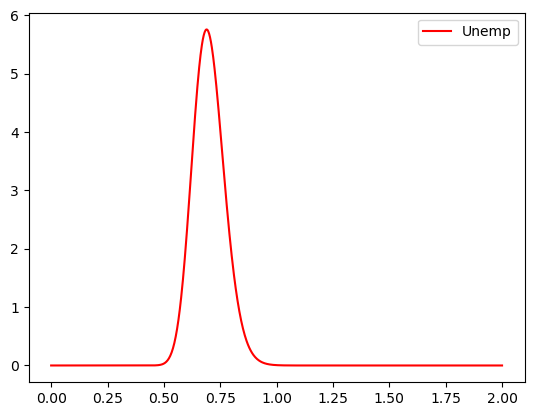

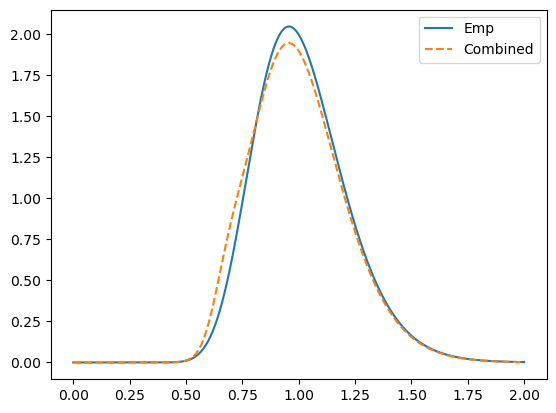

In [134]:
### Plot the two distributions
x = np.linspace(0, 2, 1000)
plt.plot(x, lognorm_dist_unemp.pdf(x), color = 'red', label = "Unemp")
plt.legend()
plt.show()

plt.plot(x, lognorm_dist_emp.pdf(x), label = "Emp")
plt.plot(x, mixture_pdf(x), linestyle='--', label = "Combined")
plt.legend()
plt.show()

In [135]:
### Step 3: To compute expectations during backwards solution, evaluate vt(mt) on the dense m-grid. Put
### these (marginal) values into a matrix that has one column.
vPnext_array = vPfuncNext(mGrid)

(0.0, 2.0)

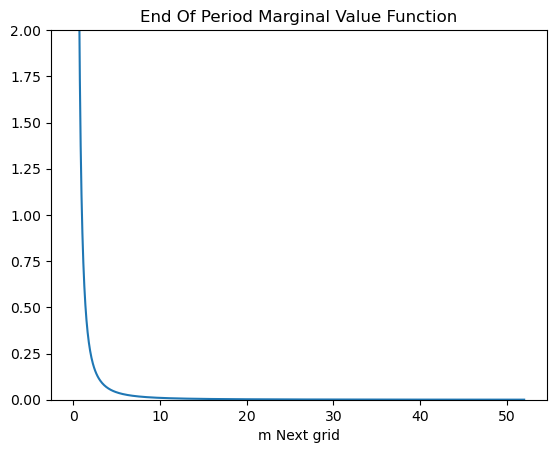

In [136]:
plt.plot(mGrid, vPnext_array)
plt.title('End Of Period Marginal Value Function')
plt.xlabel('m Next grid')
plt.ylim([0.0, 2.0])

In [137]:
### Step 4: Pre-multiply the Markov matrix by the matrix you just constructed. The resulting
###         matrix of intermediate expected values will have b row-wise.

vPnext_array_reshaped = np.reshape(vPnext_array, (vPnext_array.size, 1))
Interm_vP_Integration = np.dot(probGrid, vPnext_array_reshaped)
Interm_vPnvrs_Integration = Interm_vP_Integration.flatten() ** (-1 / CRRA)

# Interm_vPnvrsFunc = LinearInterp(
#     np.insert(bGrid, 0, 0.0), np.insert(Interm_vPnvrs, 0, 0.0)
# )  # IMPORTANT: GENERALIZE THIS ZERO

# bGrid = np.insert(bGrid, 0, 0.0)
# Interm_vPnvrs = np.insert(Interm_vPnvrs, 0, 0.0)
# Interm_vPnvrsFunc = LinearFast(np.insert(bGrid, 0, 0.0), [np.insert(Interm_vPnvrs, 0, 0.0)]) # IMPORTANT: GENERALIZE THIS ZERO

# Interm_vPnvrsFunc_Integration = LinearFast(np.insert(Interm_vPnvrs_Integration, 0, 0.0), [np.insert(bGrid, 0, 0.0)]) # IMPORTANT: GENERALIZE THIS ZERO
Interm_vPnvrsFunc_Integration = LinearFast(np.insert(Interm_vPnvrs_Integration, 0, 0.0), [np.insert(bGrid, 0, BoroCnstNat_b)]) # IMPORTANT: GENERALIZE THIS ZERO
Interm_vPfunc_Integration = MargValueFuncCRRA(Interm_vPnvrsFunc_Integration, CRRA)

In [138]:
np.insert(bGrid, 0, BoroCnstNat)

array([-5.74272582e-01, -5.73272582e-01, -5.60171382e-01, -5.46898541e-01,
       -5.33451809e-01, -5.19828910e-01, -5.06027534e-01, -4.92045343e-01,
       -4.77879969e-01, -4.63529011e-01, -4.48990039e-01, -4.34260589e-01,
       -4.19338165e-01, -4.04220240e-01, -3.88904251e-01, -3.73387605e-01,
       -3.57667672e-01, -3.41741789e-01, -3.25607258e-01, -3.09261346e-01,
       -2.92701282e-01, -2.75924261e-01, -2.58927442e-01, -2.41707943e-01,
       -2.24262849e-01, -2.06589203e-01, -1.88684011e-01, -1.70544239e-01,
       -1.52166815e-01, -1.33548624e-01, -1.14686513e-01, -9.55772853e-02,
       -7.62177040e-02, -5.66044888e-02, -3.67343171e-02, -1.66038222e-02,
        3.79040628e-03,  2.44518236e-02,  4.53839304e-02,  6.65902728e-02,
        8.80744438e-02,  1.09840083e-01,  1.31890879e-01,  1.54230566e-01,
        1.76862930e-01,  1.99791805e-01,  2.23021076e-01,  2.46554678e-01,
        2.70396598e-01,  2.94550877e-01,  3.19021605e-01,  3.43812929e-01,
        3.68929050e-01,  

In [139]:
BoroCnstNat

-0.5742725818701606

(0.0, 2.0)

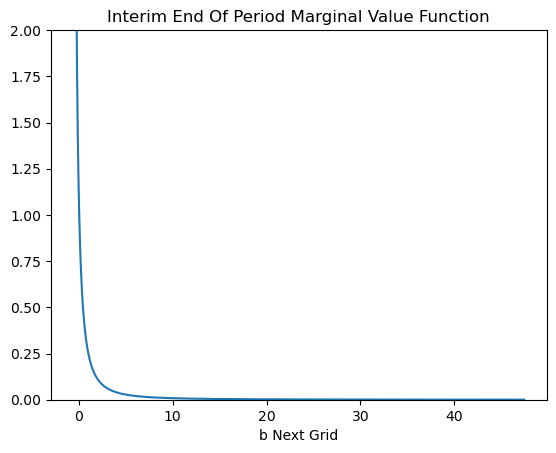

In [140]:
plt.plot(bGrid, Interm_vPfunc_Integration(bGrid))
plt.title('Interim End Of Period Marginal Value Function')
plt.xlabel('b Next Grid')
plt.ylim([0.0, 2.0])

### Comparison: shock discretization (N = 7, 31, 151) vs the transition matrix

We compare different ways of computing the interim marginal value over the transitory shock,
$$ \tilde{v}'(b) = \mathbb{E}\big[\,v'(b+\theta)\,\big|\,b\,\big] = \int v'(b+\theta)\, g(\theta)\, d\theta, $$
where $g$ is the employed/unemployed lognormal mixture used above.

- **Reference (fine integration):** a very fine trapezoidal integration of the true mixture density $g$ (treated as the "truth").
- **Discretize N = 7, 31, 151:** replace $g$ by an equiprobable discrete approximation with $N$ nodes and take a weighted sum. As $N$ grows this converges to the reference.
- **Transition matrix:** the `updateBM_TranMatrix_withUnemp` matrix applied to $v'$ on the dense `mGrid`.

> **Note (fixed notebook):** this notebook applies the $\Delta m$ (grid-spacing) weighting described above before row normalization. The transition-matrix curve should now overlay the fine-integration reference and the high-$N$ discretization, confirming that the fix removes the bias present in the original notebook.

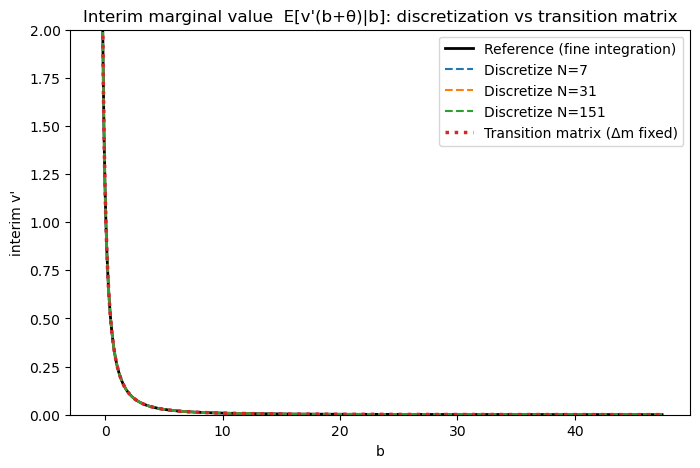

method                     mean abs dev    max abs dev   (b >= 0)
Discretize N=7                5.309e-04      1.406e-02
Discretize N=31               1.190e-04      3.259e-03
Discretize N=151              2.723e-05      7.628e-04
Transition matrix (fix)       4.736e-07      1.947e-06


In [141]:
### Compare discretization (N = 7, 31, 151) with the transition-matrix method
### for the interim marginal value over the transitory shock, E[v'(b + theta) | b].

# --- Fine reference density of the transitory shock (same mixture as the transition matrix) ---
theta_fine = np.linspace(1e-6, 8.0, 40001)
pdf_fine = mixture_pdf(theta_fine)

# The transition matrix can only represent next-period resources m = b + theta that fall
# inside the tabulated mGrid; probability mass mapping outside [mMin, mMax] is dropped and
# each row is renormalized. To isolate the *integration weighting* error (the thing the
# Delta-m fix addresses) from this common truncation, the reference and the discretization
# below truncate theta to the same valid m-window and renormalize in exactly the same way.
mMin, mMax = mGrid.min(), mGrid.max()

def interm_vP_reference(bvals):
    """E[v'(b+theta) | b+theta in [mMin,mMax]] via fine trapezoidal integration."""
    out = np.empty(len(bvals), dtype=float)
    for i, b in enumerate(bvals):
        m = b + theta_fine
        mask = (m >= mMin) & (m <= mMax)
        if mask.sum() < 2:
            out[i] = np.nan
            continue
        num = np.trapz(vPfuncNext(m[mask]) * pdf_fine[mask], theta_fine[mask])
        den = np.trapz(pdf_fine[mask], theta_fine[mask])
        out[i] = num / den
    return out

def discretize_mixture(N):
    """Equiprobable N-node discretization of the transitory-shock mixture."""
    cdf = np.concatenate(([0.0],
        np.cumsum(0.5 * (pdf_fine[1:] + pdf_fine[:-1]) * np.diff(theta_fine))))
    cdf = cdf / cdf[-1]
    q = (np.arange(N) + 0.5) / N
    nodes = np.interp(q, cdf, theta_fine)      # equiprobable node locations
    weights = np.full(N, 1.0 / N)
    return nodes, weights

def interm_vP_discretized(bvals, N):
    nodes, weights = discretize_mixture(N)
    out = np.empty(len(bvals), dtype=float)
    for i, b in enumerate(bvals):
        m = b + nodes
        mask = (m >= mMin) & (m <= mMax)
        w = weights[mask]
        if w.sum() == 0:
            out[i] = np.nan
            continue
        out[i] = np.sum(w * vPfuncNext(m[mask])) / w.sum()
    return out

# --- Transition-matrix method (uses the Delta-m-fixed updateBM_TranMatrix_withUnemp above) ---
probGrid_cmp = updateBM_TranMatrix_withUnemp(TranShk, UnempPrb, IncUnemp, IncUnemp_Std, bGrid, mGrid)
interm_vP_tm = probGrid_cmp @ vPfuncNext(mGrid)

# --- Evaluate all methods on bGrid ---
disc_counts = [7, 31, 151]
ref = interm_vP_reference(bGrid)
disc = {N: interm_vP_discretized(bGrid, N) for N in disc_counts}

# --- Plot ---
plt.figure(figsize=(8, 5))
plt.plot(bGrid, ref, 'k', lw=2, label='Reference (fine integration)')
for N in disc_counts:
    plt.plot(bGrid, disc[N], '--', label=f'Discretize N={N}')
plt.plot(bGrid, interm_vP_tm, ':', lw=2.5, color='tab:red', label='Transition matrix (Δm fixed)')
plt.title("Interim marginal value  E[v'(b+θ)|b]: discretization vs transition matrix")
plt.xlabel('b')
plt.ylabel("interim v'")
plt.ylim([0.0, 2.0])
plt.legend()
plt.show()

# --- Accuracy table (absolute deviation vs the fine-integration reference) ---
# Report over the economically relevant region b >= 0, where the interim marginal value
# is smooth (very small b sit right at the mMin edge where v' -> inf).
reg = bGrid >= 0.0

def dev(x):
    d = np.abs(np.asarray(x) - ref)[reg]
    return np.nanmean(d), np.nanmax(d)

print(f"{'method':<24}{'mean abs dev':>15}{'max abs dev':>15}   (b >= 0)")
for N in disc_counts:
    m, mx = dev(disc[N])
    print(f"{'Discretize N=' + str(N):<24}{m:>15.3e}{mx:>15.3e}")
m, mx = dev(interm_vP_tm)
print(f"{'Transition matrix (fix)':<24}{m:>15.3e}{mx:>15.3e}")

In [142]:
### Step 5: Using the pre-specified exogenous grid of a, compute expected end-of-period
###         (marginal) value using the typical discretized approximation to the permanent shock
###         distribution. For any (a) end-of-period state, there is a finite set of future (b)
###         points that can be reached under the discretization.

In [143]:
def b_nrm_next(PermGroFac, shocks, a_nrm, Rfree):
    """
    Computes normalized bank balances of the next period
    from income shocks and current normalized market resources.

    Parameters
    ----------
    shocks: [float]
        Permanent and transitory income shock levels.
    a_nrm: float
        Normalized market assets this period

    Returns
    -------
    float
        normalized market resources in the next period
    """
    return Rfree / (PermGroFac * shocks["PermShk"]) * a_nrm

In [144]:
def vp_next_Integration(shocks, a_nrm, Rfree):
    return shocks["PermShk"] ** (-CRRA) * Interm_vPfunc_Integration(
        b_nrm_next(PermGroFac, shocks, a_nrm, Rfree)
    )

In [145]:
EndOfPrdvP_Integration = (
    DiscFacEff
    * Rfree
    * PermGroFac ** (-CRRA)
    * expected(vp_next_Integration, IncShkDstn, args=(aNrmNow, Rfree))
        )

In [146]:
EndOfPrdvP[:5]

array([2094.46054733,   22.06161912,   13.61192322,   10.14875506,
          8.04862521])

In [147]:
EndOfPrdvP_TwoStep[:5]

array([14.11717726, 13.29975715, 11.768857  ,  9.85105274,  8.05700108])

In [148]:
EndOfPrdvP_Integration[:5]

array([148376.74809384, 118065.82777719,  82842.05536655,  49096.92860082,
        24287.38790648])

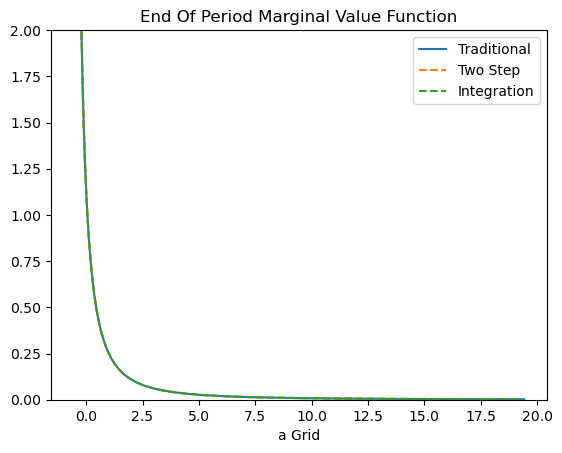

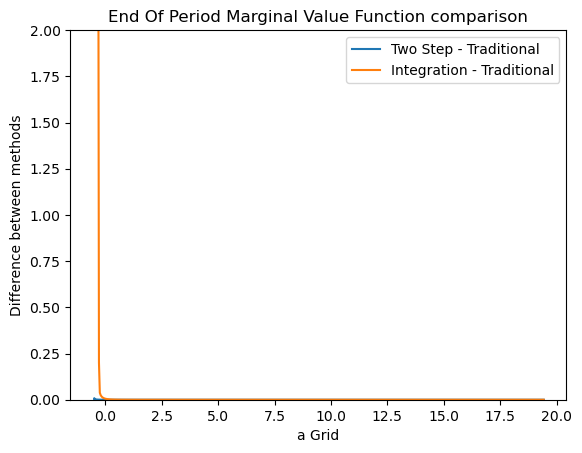

In [149]:
plt.plot(aNrmNow, EndOfPrdvP, label='Traditional')
plt.plot(aNrmNow, EndOfPrdvP_TwoStep, '--', label='Two Step')
plt.plot(aNrmNow, EndOfPrdvP_Integration, '--', label='Integration')
plt.title('End Of Period Marginal Value Function')
plt.xlabel('a Grid')
plt.ylim([0.0, 2.0])
plt.legend()
plt.show()

plt.plot(aNrmNow[1:], EndOfPrdvP_TwoStep[1:] - EndOfPrdvP[1:], label='Two Step - Traditional')
plt.plot(aNrmNow[1:], EndOfPrdvP_Integration[1:] - EndOfPrdvP[1:], label='Integration - Traditional')
plt.xlabel(r"a Grid")
plt.ylabel(r"Difference between methods")
plt.title("End Of Period Marginal Value Function comparison")
plt.ylim([0.0, 2.0])
plt.legend()
plt.show()


In [150]:
### Add zero point
aNrmNow = np.insert(aNrmNow, 0, BoroCnstNat)
EndOfPrdvP = np.insert(EndOfPrdvP, 0, np.inf)
EndOfPrdvP_TwoStep = np.insert(EndOfPrdvP_TwoStep, 0, np.inf)
EndOfPrdvP_Integration = np.insert(EndOfPrdvP_Integration, 0, np.inf)

In [151]:
### Make functions and see what the minimum level of a is
EndOfPrdvP_Func = LinearFast(EndOfPrdvP, [aNrmNow])
EndOfPrdvP_TwoStepFunc = LinearFast(EndOfPrdvP_TwoStep, [aNrmNow])
EndOfPrdvP_IntegrationFunc = LinearFast(EndOfPrdvP_Integration, [aNrmNow])





In [152]:
aNrmNow[0]

-0.5742725818701606

In [153]:
EndOfPrdvP_Func(aNrmNow[0]), EndOfPrdvP_TwoStepFunc(aNrmNow[0]), EndOfPrdvP_IntegrationFunc(aNrmNow[0])


(array(inf), array(inf), array(inf))

In [154]:
EndOfPrdvP_Func(aNrmNow[1]), EndOfPrdvP_TwoStepFunc(aNrmNow[1]), EndOfPrdvP_IntegrationFunc(aNrmNow[1])


(array(nan), array(nan), array(nan))

In [155]:
EndOfPrdvP_Func(0.0), EndOfPrdvP_TwoStepFunc(0.0), EndOfPrdvP_IntegrationFunc(0.0)


(array(1.12580036), array(1.1258028), array(1.13133232))

In [156]:
EndOfPrdvP_Func(BoroCnstNat), EndOfPrdvP_TwoStepFunc(BoroCnstNat), EndOfPrdvP_IntegrationFunc(BoroCnstNat)


(array(inf), array(inf), array(inf))

In [157]:
EndOfPrdvP_Func(BoroCnstNat-0.01), EndOfPrdvP_TwoStepFunc(BoroCnstNat-0.01), EndOfPrdvP_IntegrationFunc(BoroCnstNat-0.01)


(array(inf), array(inf), array(inf))

In [158]:
BoroCnstNat

-0.5742725818701606

In [159]:
# Construct the consumption function in two ways: standard approach and new approach
cNrm = EndOfPrdvP ** (-1 / CRRA)
mNrm = aNrmNow + cNrm
cFunc = LinearInterp(np.insert(mNrm, 0, BoroCnstNat), np.insert(cNrm, 0, 0.0))

cNrm_TwoStep = EndOfPrdvP_TwoStep ** (-1 / CRRA)
mNrm_TwoStep = aNrmNow + cNrm_TwoStep
cFunc_TwoStep = LinearInterp(np.insert(mNrm_TwoStep, 0, BoroCnstNat), np.insert(cNrm_TwoStep, 0, 0.0))

cNrm_Integration = EndOfPrdvP_Integration ** (-1 / CRRA)
mNrm_Integration = aNrmNow + cNrm_Integration
cFunc_Integration = LinearInterp(np.insert(mNrm_Integration, 0, BoroCnstNat), np.insert(cNrm_Integration, 0, 0.0))

In [160]:
cNrm[:5]

array([0.        , 0.02185063, 0.21290277, 0.27104429, 0.31390166])

In [161]:
mNrm[:5]

array([-0.57427258, -0.55142195, -0.34119844, -0.2627637 , -0.19840199])

In [162]:
cNrm_Integration[:5]

array([0.        , 0.00259607, 0.0029103 , 0.00347436, 0.00451308])

In [163]:
mNrm_Integration[:5]

array([-0.57427258, -0.57067651, -0.55119091, -0.53033363, -0.50779057])

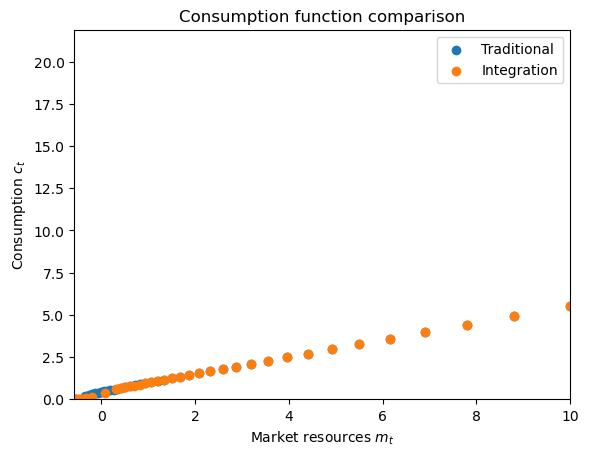

In [164]:
plt.scatter(mNrm, cNrm, label='Traditional')
plt.scatter(mNrm_Integration, cNrm_Integration, label='Integration')
plt.xlabel(r"Market resources $m_t$")
plt.ylabel(r"Consumption $c_t$")
plt.xlim(BoroCnstNat, 10.0)
plt.ylim(0.0, None)
plt.title("Consumption function comparison")
plt.legend()
plt.show()

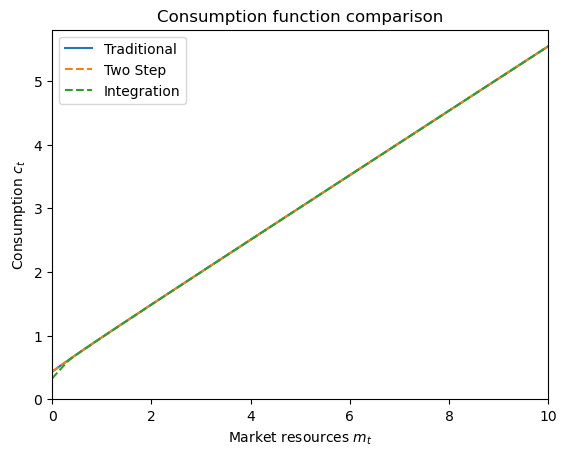

In [165]:
# Plot a comparison of the two consumption functions using different integration methods
M = np.linspace(0.0, 10.0, 201)
C0 = cFunc(M)
C1 = cFunc_TwoStep(M)
C2 = cFunc_Integration(M)
plt.plot(M, C0, label='Traditional')
plt.plot(M, C1, '--', label='Two Step')
plt.plot(M, C2, '--', label='Integration')
plt.xlabel(r"Market resources $m_t$")
plt.ylabel(r"Consumption $c_t$")
plt.xlim(0.0, 10.0)
plt.ylim(0.0, None)
plt.title("Consumption function comparison")
plt.legend()
plt.show()

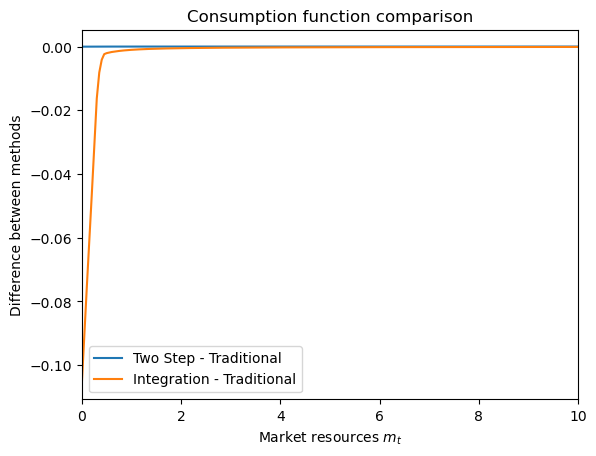

In [166]:
plt.plot(M, C1 - C0, label='Two Step - Traditional')
plt.plot(M, C2 - C0, label='Integration - Traditional')
plt.xlabel(r"Market resources $m_t$")
plt.ylabel(r"Difference between methods")
plt.title("Consumption function comparison")
plt.xlim(0.0, 10.0)
plt.legend()
plt.show()